# Jet energy

Jets enter the signal selection in one place, the lepton-jet isolation
(`SidmProcessor.build_lepton_jets`):

$$ I = \frac{E_{\rm jet}}{E_{\rm LJ}}\,(1 - f_{\rm lep}), \qquad f_{\rm lep} = f_{\rm chEM} + f_{\rm neEM} + f_\mu, $$

where $E_{\rm jet}$ is the energy of the AK4 CHS jet nearest the lepton jet ($\Delta R < 0.4$),
and $f_{\rm lep}$ the fraction of its energy carried by electrons, photons and muons (no
matched jet: $I = 0$). The energy fractions are fractions of the uncorrected jet energy, so
the numerator is the jet energy correction times the uncorrected energy of the jet's
hadrons, and changing the jet energy scale by a factor $1 + \delta$ multiplies $I$ by the
same factor. The matching does not change, since it uses only directions.

The jet energy corrections (Summer19UL18_V5) are already applied in NanoAODv9. The jet energy
resolution (JER) smearing that simulated jets normally get is not applied (`jet_energy` in
`sidm/configs/corrections.yaml`). This notebook:

1. looks at the jets matched to the lepton jets;
2. asks which jet energy scale (JES) uncertainty applies to them;
3. propagates the standard variations, JES up and down and the JER smearing, to the signal yield;
4. builds a conservative envelope for the hadronic part of these jets;
5. says what to assign.

Inputs: the merged outputs of the corrections campaign, whose `lj_isolation_*` histograms
recompute the isolation of every lepton jet with the matched jet varied
(`hists.lj_isolation_variant`). Simulation only. As in `01_pileup.ipynb`, the yields are
those of the campaign's `2mu2e_sr` and `4mu_sr` channels, which are inclusive in the isolation.

In [1]:
import os, sys, warnings
import numpy as np
import hist
import matplotlib.pyplot as plt
import mplhep as hep

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import utilities
from sidm.tools.corrections import Corrections
from sidm.studies.corrections import corrections_study as study
from sidm.studies.systematics import systematics_study as sysstudy

warnings.filterwarnings("ignore", module="coffea")
utilities.set_plot_style(dpi=100)
BLUE, ORANGE, AQUA, GRAY, BLACK = study.BLUE, study.ORANGE, study.AQUA, study.GRAY, study.BLACK
SIGNALS = study.signal_points()
LIMIT = set(sysstudy.limit_grid(SIGNALS))
print(f"{len(SIGNALS)} signal points, {len(LIMIT)} of them on the limit grid")

180 signal points, 96 of them on the limit grid


## Samples

In [2]:
VARIANTS = ("analysis", "jes_up", "jes_down", "jer", "raw")
SCALES = (1.03, 1.05, 1.10)
SHOWN = {"2Mu2E": "2Mu2E_500GeV_1p2GeV_1p9mm", "4Mu": "4Mu_500GeV_1p2GeV_1p9mm"}
rows, shown = {}, {}
for s in SIGNALS:
    out = study.load([s])[s]
    fs = study.parse_point(s)["final_state"]
    ch = sysstudy.CHANNEL[fs]
    nominal = lambda name: study.syst_hist(out["hists"][name], "nominal", ch)[{"channel": ch}]
    iso = {v: nominal(f"lj_isolation_{v}") for v in VARIANTS}
    jet = nominal("lj_has_matched_jet")
    lepjec = nominal("lj_matched_jet_lepfrac_jec")
    lepfrac, jec = lepjec.project("lepfrac"), lepjec.project("jec")
    rows[s] = {
        "fs": fs,
        "matched": jet[{"has_jet": True}].value / jet.sum().value,
        "lepfrac": float(np.average(lepfrac.axes[0].centers, weights=lepfrac.values())),
        "jec": float(np.average(jec.axes[0].centers, weights=jec.values())),
        "eff": {name: sysstudy.iso_efficiency(iso["analysis"], is_mu, cut)
                for name, (is_mu, cut) in sysstudy.ISO_CUTS[fs].items()},
        "shift": {v: sysstudy.event_iso_shift(iso["analysis"], iso[v], fs) for v in VARIANTS[1:]},
        "scaled": {k: sysstudy.event_iso_shift(iso["analysis"], iso["analysis"], fs, scale=k) for k in SCALES},
    }
    if s in SHOWN.values():
        shown[s] = {"iso": iso, "lepfrac": lepfrac, "jec": jec}
    del out
print(f"read {len(rows)} signal points")

read 180 signal points


## 1. The matched jets

2Mu2E : lepton jets with a matched jet 76 to 100% (median 98%); mean lepton fraction of the matched jet 0.84 to 0.96; mean JEC factor 1.028 to 1.085
        region-A isolation efficiency of the muon LJ: 98.0 to 100.0% (median 98.9%)
        region-A isolation efficiency of the other LJ: 81.3 to 97.4% (median 93.5%)
4Mu   : lepton jets with a matched jet 61 to 100% (median 95%); mean lepton fraction of the matched jet 0.82 to 0.98; mean JEC factor 1.018 to 1.083
        region-A isolation efficiency of the muon LJ: 95.0 to 99.6% (median 98.5%)
        region-A isolation efficiency of the other LJ: 98.9 to 99.8% (median 99.4%)


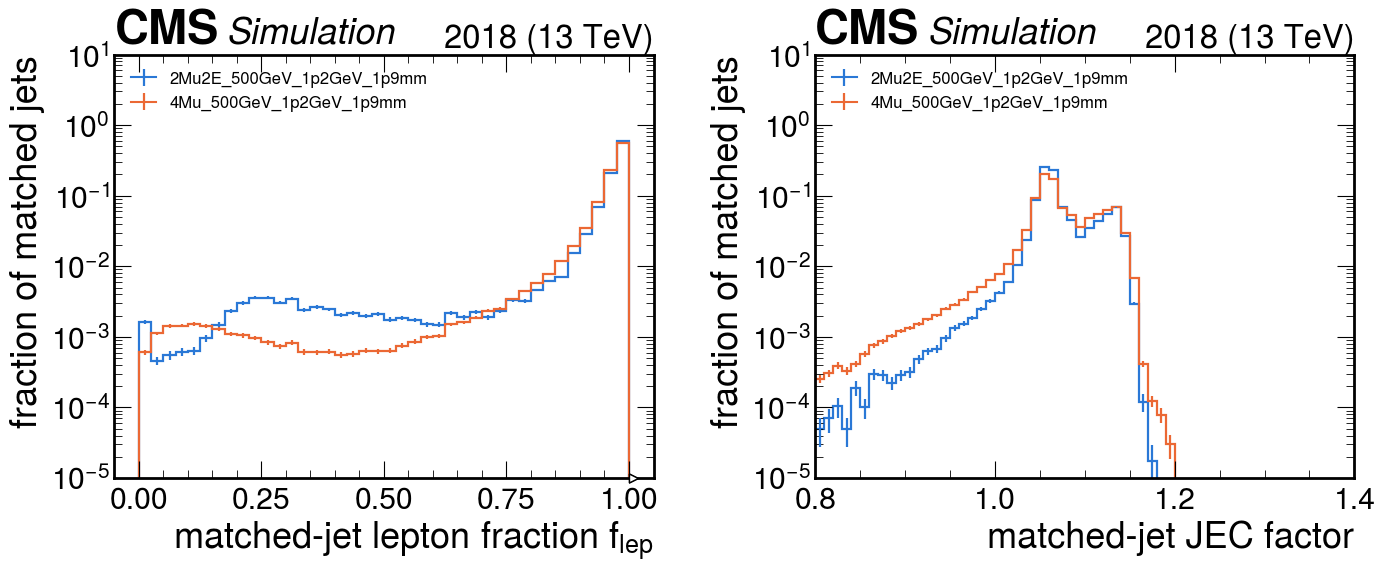

In [3]:
for fs in ("2Mu2E", "4Mu"):
    r = [rows[s] for s in SIGNALS if rows[s]["fs"] == fs]
    m, l, j = (np.array([x[k] for x in r]) for k in ("matched", "lepfrac", "jec"))
    print(f"{fs:6s}: lepton jets with a matched jet {100 * m.min():.0f} to {100 * m.max():.0f}% "
          f"(median {100 * np.median(m):.0f}%); mean lepton fraction of the matched jet {l.min():.2f} to {l.max():.2f}; "
          f"mean JEC factor {j.min():.3f} to {j.max():.3f}")
    for name in sysstudy.ISO_CUTS[fs]:
        e = np.array([x["eff"][name] for x in r])
        print(f"        region-A isolation efficiency of the {name}: {100 * e.min():.1f} to {100 * e.max():.1f}% "
              f"(median {100 * np.median(e):.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"wspace": 0.3})
for (fs, s), color in zip(SHOWN.items(), (BLUE, ORANGE)):
    hep.histplot(study.fractions(shown[s]["lepfrac"]), ax=axes[0], color=color, lw=1.6, label=s)
    hep.histplot(study.fractions(shown[s]["jec"]), ax=axes[1], color=color, lw=1.6, label=s)
axes[0].set_xlabel(r"matched-jet lepton fraction $f_{\rm lep}$")
axes[1].set_xlabel("matched-jet JEC factor")
axes[1].set_xlim(0.8, 1.4)
for ax in axes:
    ax.set_ylabel("fraction of matched jets")
    ax.set_yscale("log")
    ax.set_ylim(1e-5, 10)
    ax.legend(fontsize=12, loc="upper left")
study.cms_label(axes)
plt.show()

Most signal lepton jets have a matched jet, and that jet is mostly the lepton jet itself:
on average about 92% of its energy is leptons. The isolation measures the small hadronic
remainder, a few GeV for a lepton jet of a few tens of GeV.

## 2. Which JES uncertainty

The JES uncertainty is a function of the jet $p_T$ and $\eta$ (the total uncertainty of
Summer19UL18_V5, from the pinned correction file). Evaluated at the $p_T$ of the matched jet,
which includes its leptons ($p_T > 30$ GeV, often much more), it is 2 to 6% at 30 GeV and
below 3.5% above 100 GeV. But the energy that enters the isolation is that of the hadrons,
whose $p_T$ is a few GeV, below the lowest $p_T$ of the calibration (10 GeV), where the
uncertainty is 5% in the barrel and 11% at $|\eta| = 2.4$.

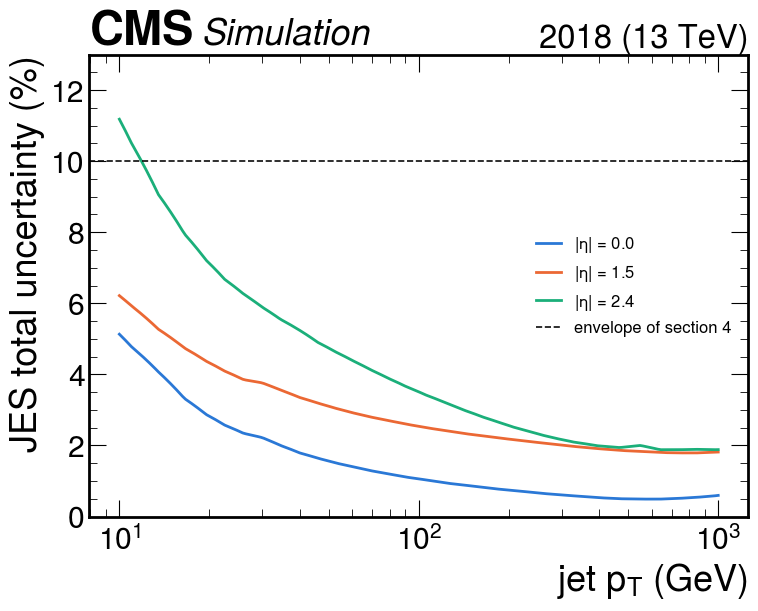

 pT (GeV) |eta|=0.0  |eta|=1.5  |eta|=2.4 
       10     5.13%     6.21%    11.18%
       30     2.22%     3.76%     5.89%
      100     1.06%     2.54%     3.51%
      300     0.61%     2.01%     2.17%


In [4]:
corr = Corrections("2018", names=[])
entry = corr.entry("jet_energy")
jes = corr.correction(entry["file"], entry["jes_uncertainty"])
pt = np.geomspace(10, 1000, 200)
fig, ax = plt.subplots(figsize=(8.5, 6))
for eta, color in ((0.0, BLUE), (1.5, ORANGE), (2.4, AQUA)):
    ax.plot(pt, 100 * jes.evaluate(np.full_like(pt, eta), pt), color=color, lw=2, label=rf"$|\eta|$ = {eta}")
ax.axhline(10, color=BLACK, ls="--", lw=1.2, label="envelope of section 4")
ax.set_xscale("log")
ax.set_xlabel(r"jet $p_T$ (GeV)")
ax.set_ylabel("JES total uncertainty (%)")
ax.set_ylim(0, 13)
ax.legend(fontsize=12)
study.cms_label(ax)
plt.show()

print(f"{'pT (GeV)':>9s} " + " ".join(f"|eta|={e:<4}" for e in (0.0, 1.5, 2.4)))
for p in (10, 30, 100, 300):
    print(f"{p:9d} " + " ".join(f"{100 * jes.evaluate(e, float(p)):8.2f}%" for e in (0.0, 1.5, 2.4)))

## 3. The standard variations

`jes_up` and `jes_down` shift the matched jet by its total JES uncertainty at its own $p_T$
and $\eta$; `jer` applies the hybrid JER smearing that the nominal simulation does not have
(a jet matched to a generator jet has its difference from it scaled by the JER scale
factor, any other jet is smeared stochastically). Each gives a
different isolation for every lepton jet; the change of the region-A efficiency, summed
over the two lepton jets, is the change of the signal yield. The isolation distributions near
the cuts for two points:

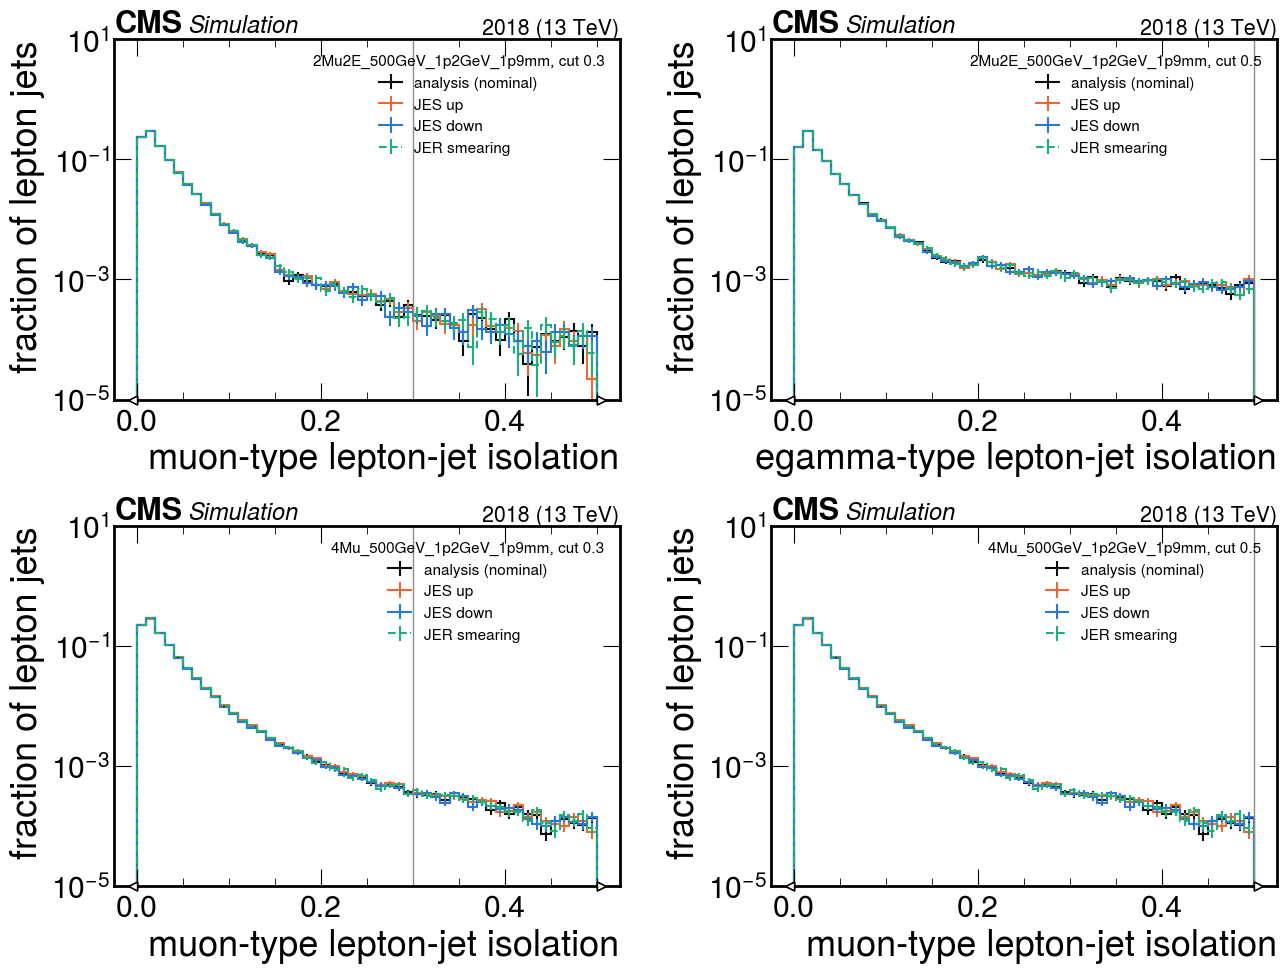

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11), gridspec_kw={"hspace": 0.35, "wspace": 0.3})
STYLES = {"analysis": (BLACK, "-", "analysis (nominal)"), "jes_up": (ORANGE, "-", "JES up"),
          "jes_down": (BLUE, "-", "JES down"), "jer": (AQUA, "--", "JER smearing")}
for row_axes, (fs, s) in zip(axes, SHOWN.items()):
    for ax, (name, (is_mu, cut)) in zip(row_axes, sysstudy.ISO_CUTS[fs].items()):
        for v, (color, ls, label) in STYLES.items():
            h = shown[s]["iso"][v][{"is_mu": is_mu}]
            hep.histplot(study.fractions(h), ax=ax, color=color, ls=ls, lw=1.5, label=label)
        ax.axvline(cut, color=GRAY, lw=1)
        ax.set_yscale("log")
        ax.set_ylim(1e-5, 10)
        ax.set_xlabel(f"{'muon-type' if is_mu else 'egamma-type'} lepton-jet isolation")
        ax.set_ylabel("fraction of lepton jets")
        ax.legend(title=f"{s}, cut {cut}", fontsize=11, title_fontsize=11, loc="upper right")
study.cms_label(axes)
plt.show()

In [6]:
def ranges(values):
    v = 100 * np.asarray(values)
    return f"{np.median(v):+.2f}% median, {v.min():+.2f} to {v.max():+.2f}%"

for fs in ("2Mu2E", "4Mu"):
    for label, points in (("all points", [s for s in SIGNALS if rows[s]["fs"] == fs]),
                          ("limit grid", [s for s in LIMIT if rows[s]["fs"] == fs])):
        print(f"{fs} {label} ({len(points)}):")
        for v in ("jes_up", "jes_down", "jer"):
            print(f"    {v:9s} yield change {ranges([rows[s]['shift'][v] for s in points])}")

2Mu2E all points (90):
    jes_up    yield change -0.08% median, -1.22 to +0.00%
    jes_down  yield change +0.10% median, -0.00 to +0.96%
    jer       yield change -0.11% median, -1.23 to +0.54%
2Mu2E limit grid (48):
    jes_up    yield change -0.07% median, -0.37 to -0.00%
    jes_down  yield change +0.08% median, -0.00 to +0.30%
    jer       yield change -0.10% median, -0.43 to +0.00%
4Mu all points (90):
    jes_up    yield change -0.06% median, -0.55 to -0.00%
    jes_down  yield change +0.08% median, -0.00 to +0.50%
    jer       yield change -0.03% median, -0.43 to +0.06%
4Mu limit grid (48):
    jes_up    yield change -0.04% median, -0.24 to -0.00%
    jes_down  yield change +0.04% median, -0.00 to +0.18%
    jer       yield change -0.01% median, -0.18 to +0.05%


Most signal lepton jets sit far below the cuts, so the standard variations move the yield by
a tenth of a percent at a typical point and by about 1% at most. JES up and down are nearly
mirror images. The JER smearing mostly lowers the efficiency: the distribution falls
steeply towards the cut, so smearing moves more lepton jets up across it than down.

## 4. An envelope for the hadronic part

Section 2 argues that the uncertainty of the energy measured in the isolation is that of
jets of a few GeV, not that of the matched jet. A scale of $1 \pm 10\%$ on every isolation,
about the uncertainty at the lowest calibrated $p_T$ (5% in the barrel, 11% at
$|\eta| = 2.4$), is a conservative envelope for it. Since $I$ is proportional to the jet energy, a scale $k$ is
the same as moving the cut from $c$ to $c/k$ (`systematics_study.iso_efficiency`), so it can be
read off the nominal isolation distributions. Only $k > 1$ is computed exactly, since the
histograms stop at 0.5 and $k < 1$ would move the 0.5 cut above it.

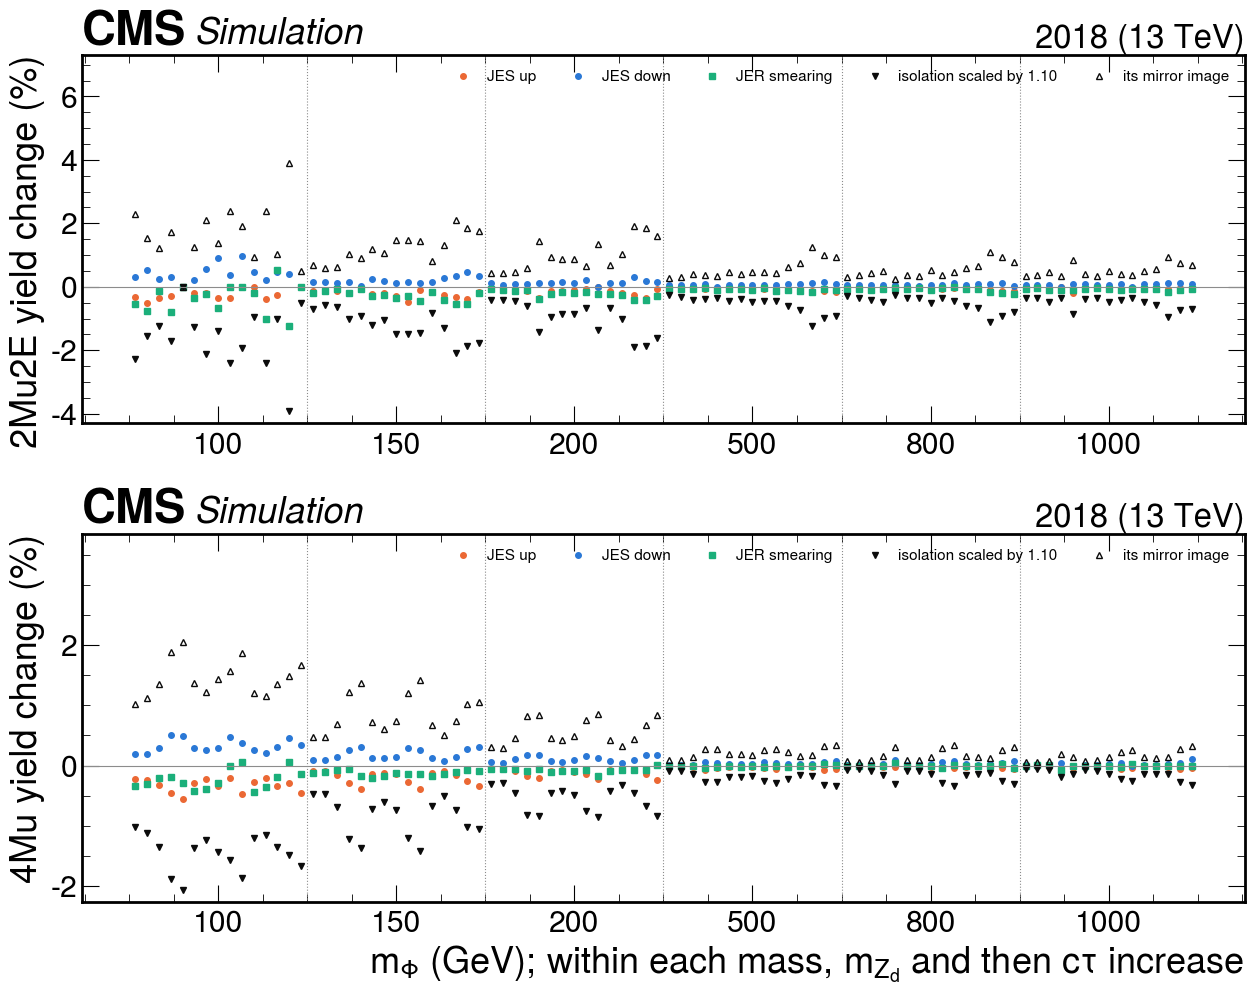

2Mu2E  all points : envelope 0.69% median, 3.91% max; it covers the largest standard variation at 89 of 90 points
2Mu2E  limit grid : envelope 0.51% median, 1.90% max; it covers the largest standard variation at 48 of 48 points
        scale 1.03, limit grid: -0.17% median, -0.67 to -0.08%
        scale 1.05, limit grid: -0.28% median, -1.10 to -0.14%
        scale 1.10, limit grid: -0.51% median, -1.90 to -0.25%
4Mu    all points : envelope 0.33% median, 2.06% max; it covers the largest standard variation at 90 of 90 points
4Mu    limit grid : envelope 0.26% median, 0.85% max; it covers the largest standard variation at 48 of 48 points
        scale 1.03, limit grid: -0.08% median, -0.28 to -0.02%
        scale 1.05, limit grid: -0.13% median, -0.43 to -0.03%
        scale 1.10, limit grid: -0.26% median, -0.85 to -0.06%


In [7]:
fig, axes = plt.subplots(2, 1, figsize=(15, 11), gridspec_kw={"hspace": 0.3})
for ax, fs in zip(axes, ("2Mu2E", "4Mu")):
    points = sysstudy.ordered_points(SIGNALS, fs)
    x = np.arange(len(points))
    for key, color, marker, label in (("jes_up", ORANGE, "o", "JES up"), ("jes_down", BLUE, "o", "JES down"),
                                      ("jer", AQUA, "s", "JER smearing")):
        ax.plot(x, [100 * rows[s]["shift"][key] for s in points], marker, ms=4, color=color, label=label)
    ax.plot(x, [100 * rows[s]["scaled"][1.10] for s in points], "v", ms=5, color=BLACK, label="isolation scaled by 1.10")
    ax.plot(x, [-100 * rows[s]["scaled"][1.10] for s in points], "^", ms=5, mfc="none", color=BLACK,
            label="its mirror image")
    ax.axhline(0, color=GRAY, lw=0.8)
    sysstudy.mass_ticks(ax, points, label=ax is axes[-1])
    ax.set_ylabel(f"{fs} yield change (%)")
    sysstudy.headroom(ax)
    ax.legend(ncol=5, fontsize=11, loc="upper right")
study.cms_label(axes)
plt.show()

for fs in ("2Mu2E", "4Mu"):
    for label, points in (("all points", [s for s in SIGNALS if rows[s]["fs"] == fs]),
                          ("limit grid", [s for s in LIMIT if rows[s]["fs"] == fs])):
        env = np.array([abs(rows[s]["scaled"][1.10]) for s in points])
        std = np.array([max(abs(rows[s]["shift"][v]) for v in ("jes_up", "jes_down", "jer")) for s in points])
        print(f"{fs:6s} {label:11s}: envelope {100 * np.median(env):.2f}% median, {100 * env.max():.2f}% max; "
              f"it covers the largest standard variation at {np.sum(env >= std)} of {len(points)} points")
    for k in SCALES:
        v = [rows[s]["scaled"][k] for s in LIMIT if rows[s]["fs"] == fs]
        print(f"        scale {k:.2f}, limit grid: {ranges(v)}")

The envelope is a few tenths of a percent at a typical point and at most about 2% on the
limit grid. It is larger than every standard variation at every point of the limit grid
(and at all but one of the other points), so one nuisance from it covers JES and JER
together.

The `raw` variant, the isolation computed without the JEC, is not a systematic variation
but a different definition of the isolation; whether the isolation should use the raw jet
energy is an open question of the corrections study (README, open item 5). Its effect:

In [8]:
for fs in ("2Mu2E", "4Mu"):
    print(f"{fs:6s}: yield change with the uncorrected jet energy, limit grid: "
          f"{ranges([rows[s]['shift']['raw'] for s in LIMIT if rows[s]['fs'] == fs])}")

2Mu2E : yield change with the uncorrected jet energy, limit grid: +0.36% median, -0.15 to +1.11%
4Mu   : yield change with the uncorrected jet energy, limit grid: +0.09% median, -0.17 to +0.24%


## 5. What to assign

* One log-normal nuisance, `CMS_jet_energy`, on the signal only (the background is estimated
  from data), with the same name in every card: correlated between 2mu2e and 4mu, across
  signal points and across the ABCD regions.
* Its value for each point is the loss of signal yield when the isolation is scaled by
  1.10, taken symmetric: the jet energy scale of the few-GeV hadronic part of the matched
  jets, which covers the standard JES and JER variations at every point of the limit grid.
  There it is a few tenths of a percent for a typical point and about 2% at most.
* The values must be read at the selection of the limits: the same isolation cuts, on the
  same two lepton jets, in region A. A per-event histogram of the two isolations, filled
  for the nominal and the scaled isolation, would give them exactly; the per-lepton-jet sum
  used here is exact to first order and close at efficiencies above 90%.
* Separate JES and JER nuisances, from `jes_up`/`jes_down` and `jer`, are the alternative if
  the group prefers the standard prescription; they are below the envelope everywhere.